In [1]:
import numpy as np
import matplotlib.pyplot as plt

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

In [2]:
def predict_surge(demand, drivers, w1, w2, b):
    z = w1 * demand + w2 * drivers + b
    return sigmoid(z)

w1, w2, b = 1, -1.5, -10

In [3]:
orders = [
    (40, 5), (10, 20), (30, 10), (20, 10),
    (45, 25), (15, 2), (35, 15), (5, 25),
]

for demand, drivers in orders:
    p = predict_surge(demand, drivers, w1, w2, b)
    decision = "SURGE" if p >= 0.5 else "no surge"
    print(f"demand={demand:>2}, drivers={drivers:>2} -> P(surge)={p:.4f} -> {decision}")

demand=40, drivers= 5 -> P(surge)=1.0000 -> SURGE
demand=10, drivers=20 -> P(surge)=0.0000 -> no surge
demand=30, drivers=10 -> P(surge)=0.9933 -> SURGE
demand=20, drivers=10 -> P(surge)=0.0067 -> no surge
demand=45, drivers=25 -> P(surge)=0.0759 -> no surge
demand=15, drivers= 2 -> P(surge)=0.8808 -> SURGE
demand=35, drivers=15 -> P(surge)=0.9241 -> SURGE
demand= 5, drivers=25 -> P(surge)=0.0000 -> no surge


In [4]:
def decision_boundary(demand_values, w1, w2, b):
    # solving w1*x1 + w2*x2 + b = 0 for x2
    return (w1 * demand_values + b) / -w2

demand_range = np.linspace(0, 50, 300)
driver_boundary = decision_boundary(demand_range, w1, w2, b)

# spot check against the hand-worked formula: demand = 10 + 1.5*drivers
for drv in [0, 10, 20]:
    expected_demand = 10 + 1.5*drv
    print(f"drivers={drv} -> boundary demand (hand formula) = {expected_demand}")

drivers=0 -> boundary demand (hand formula) = 10.0
drivers=10 -> boundary demand (hand formula) = 25.0
drivers=20 -> boundary demand (hand formula) = 40.0


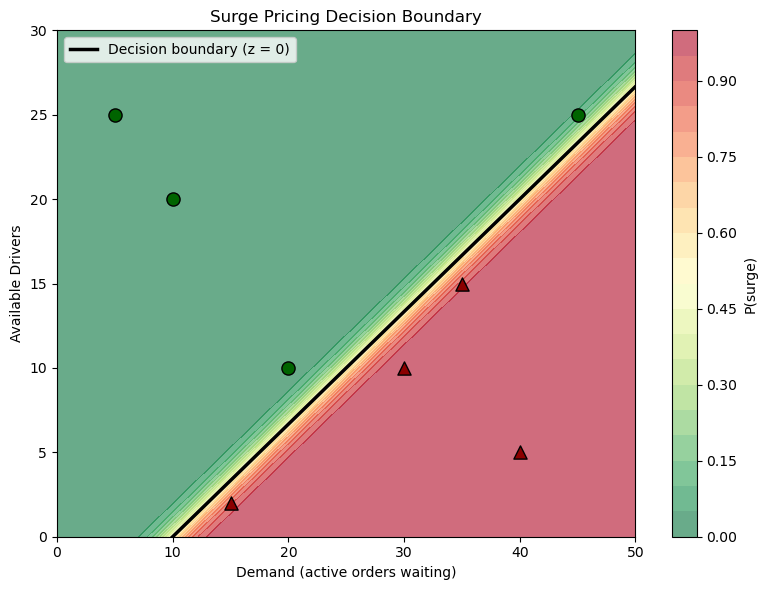

In [5]:
demand_grid = np.linspace(0, 50, 300)
driver_grid = np.linspace(0, 30, 300)
D, R = np.meshgrid(demand_grid, driver_grid)
P = sigmoid(w1*D + w2*R + b)

fig, ax = plt.subplots(figsize=(8, 6))
c = ax.contourf(D, R, P, levels=20, cmap='RdYlGn_r', alpha=0.6)
plt.colorbar(c, label='P(surge)')

ax.plot(demand_range, driver_boundary, color='black', linewidth=2.5, label='Decision boundary (z = 0)')

for demand, drivers in orders:
    p = predict_surge(demand, drivers, w1, w2, b)
    color = 'darkred' if p >= 0.5 else 'darkgreen'
    marker = '^' if p >= 0.5 else 'o'
    ax.scatter(demand, drivers, color=color, s=90, marker=marker, edgecolor='black', zorder=5)

ax.set_xlim(0, 50)
ax.set_ylim(0, 30)
ax.set_xlabel('Demand (active orders waiting)')
ax.set_ylabel('Available Drivers')
ax.set_title('Surge Pricing Decision Boundary')
ax.legend(loc='upper left')
plt.tight_layout()
plt.savefig('surge_boundary_main.png', dpi=150)
plt.show()

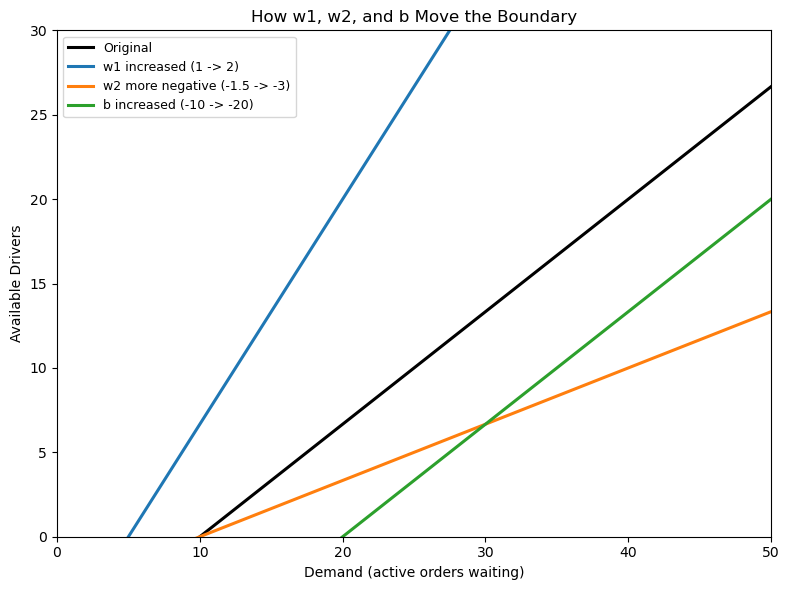

In [6]:
variants = [
    ("Original", dict(w1=1, w2=-1.5, b=-10), 'black'),
    ("w1 increased (1 -> 2)", dict(w1=2, w2=-1.5, b=-10), 'tab:blue'),
    ("w2 more negative (-1.5 -> -3)", dict(w1=1, w2=-3, b=-10), 'tab:orange'),
    ("b increased (-10 -> -20)", dict(w1=1, w2=-1.5, b=-20), 'tab:green'),
]

fig, ax = plt.subplots(figsize=(8, 6))
for label, p, color in variants:
    boundary = decision_boundary(demand_range, p['w1'], p['w2'], p['b'])
    ax.plot(demand_range, boundary, label=label, color=color, linewidth=2.2)

ax.set_xlim(0, 50)
ax.set_ylim(0, 30)
ax.set_xlabel('Demand (active orders waiting)')
ax.set_ylabel('Available Drivers')
ax.set_title('How w1, w2, and b Move the Boundary')
ax.legend(loc='upper left', fontsize=9)
plt.tight_layout()
plt.savefig('surge_boundary_variants.png', dpi=150)
plt.show()